In [1]:
# ============================================================
# Notebook 7: Ablation Study
# Which choices actually matter? We change ONE setting at a time
# and measure the effect.
#
# Run notebook 3 first: this notebook uses the PGD-trained model it saves.
#
# CELL 1 - Setup (shared by every cell in this notebook)
# ============================================================

import os
import json
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from tqdm import tqdm

torch.manual_seed(42)
np.random.seed(42)

# -- Same SimpleCNN as in notebooks 1-3 --
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1   = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2   = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool    = nn.MaxPool2d(2, 2)
        self.relu    = nn.ReLU()
        self.fc1     = nn.Linear(64 * 7 * 7, 128)
        self.fc2     = nn.Linear(128, 10)
        self.dropout = nn.Dropout(0.25)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = x.view(-1, 64 * 7 * 7)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)

# -- MNIST normalisation (same values as notebooks 1-3) --
MEAN, STD = 0.1307, 0.3081

# A real image has pixel values between 0 (black) and 1 (white).
# After normalisation those limits become X_MIN and X_MAX.
# Any image we create must stay inside this range to be a valid image.
X_MIN = (0.0 - MEAN) / STD
X_MAX = (1.0 - MEAN) / STD

def to_tensors(dataset):
    """Load a whole MNIST split into memory as normalised tensors.
    Gives exactly the same values as ToTensor() + Normalize(), but is much faster."""
    x = dataset.data.float().div(255).sub(MEAN).div(STD).unsqueeze(1)
    y = dataset.targets.clone()
    return x, y

def to_pixels(x):
    """Undo the normalisation: back to pixel values between 0 and 1."""
    return (x * STD + MEAN).clamp(0, 1)

train_set = torchvision.datasets.MNIST(root='../data', train=True,  download=False)
test_set  = torchvision.datasets.MNIST(root='../data', train=False, download=False)
X_train, y_train = to_tensors(train_set)
X_test,  y_test  = to_tensors(test_set)

def predict(model, X, batch_size=1000):
    """Return the model's raw outputs (logits) for a set of images."""
    model.eval()
    outputs = []
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            outputs.append(model(X[i:i + batch_size]))
    return torch.cat(outputs)

def accuracy(model, X, y):
    """Accuracy in percent."""
    return 100.0 * (predict(model, X).argmax(1) == y).float().mean().item()

def train_model(X, y, epochs=3, seed=0, batch_size=64, lr=0.001, desc="Training"):
    """Train a fresh SimpleCNN with the same settings as the baseline in notebook 1."""
    torch.manual_seed(seed)
    model = SimpleCNN()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    n = len(X)
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(n)
        for i in tqdm(range(0, n, batch_size), desc=f"{desc} epoch {epoch+1}/{epochs}"):
            idx = order[i:i + batch_size]
            optimizer.zero_grad()
            loss = criterion(model(X[idx]), y[idx])
            loss.backward()
            optimizer.step()
    model.eval()
    return model

def load_model(path):
    model = SimpleCNN()
    model.load_state_dict(torch.load(path, weights_only=True))
    model.eval()
    return model

os.makedirs('../figures', exist_ok=True)
os.makedirs('../results', exist_ok=True)
os.makedirs('../models',  exist_ok=True)

baseline_model = load_model('../models/mnist_cnn_baseline.pth')
print(f"Training images: {len(X_train)}   Test images: {len(X_test)}")
print(f"Baseline model clean accuracy: {accuracy(baseline_model, X_test, y_test):.2f}%")

Training images: 60000   Test images: 10000
Baseline model clean accuracy: 99.09%


In [2]:
# CELL 2 - Attacks and helpers used in this notebook
#
# An "ablation study" changes one ingredient of a method while keeping
# everything else fixed, to find out which ingredients are responsible
# for the result. We run four ablations:
#   A. Attack strength : how many PGD steps does the attacker need?
#   B. Training attack : how many PGD steps are needed DURING adversarial training?
#   C. Training budget : what happens if the model is trained for a different
#                        epsilon than it is attacked with?
#   D. Preprocessing   : do the input-preprocessing defenses work at any strength?
#
# All epsilon values are in pixel units (0 = black, 1 = white), as in notebooks 2-6.

EPSILON = 0.3          # the standard MNIST attack budget
N_EVAL  = 2000         # test images used for each measurement

X_eval, y_eval = X_test[:N_EVAL], y_test[:N_EVAL]

def fgsm_attack(model, x, y, epsilon):
    x = x.clone().requires_grad_(True)
    loss = nn.CrossEntropyLoss()(model(x), y)
    grad, = torch.autograd.grad(loss, x)
    return torch.clamp(x + (epsilon / STD) * grad.sign(), X_MIN, X_MAX).detach()

def pgd_attack(model, x, y, epsilon, steps=40, alpha=None, random_start=True):
    """PGD. Step size defaults to 2.5 * epsilon / steps (at least epsilon / 10),
    so that even a short attack can reach the edge of the allowed region."""
    if alpha is None:
        alpha = max(epsilon / 10, 2.5 * epsilon / steps)
    eps_n, alpha_n = epsilon / STD, alpha / STD
    adv = x.clone()
    if random_start:
        adv = adv + torch.empty_like(x).uniform_(-eps_n, eps_n)
    adv = torch.clamp(adv, X_MIN, X_MAX)
    for _ in range(steps):
        adv.requires_grad_(True)
        loss = nn.CrossEntropyLoss()(model(adv), y)
        grad, = torch.autograd.grad(loss, adv)
        adv = x + torch.clamp(adv.detach() + alpha_n * grad.sign() - x, -eps_n, eps_n)
        adv = torch.clamp(adv, X_MIN, X_MAX).detach()
    return adv

def attack_in_batches(attack, model, x, y, batch_size=500):
    torch.manual_seed(0)
    return torch.cat([attack(model, x[i:i + batch_size], y[i:i + batch_size])
                      for i in range(0, len(x), batch_size)])

def robust_accuracy(model, attack):
    """Accuracy (%) on the evaluation images after applying `attack`."""
    adv = attack_in_batches(attack, model, X_eval, y_eval)
    return accuracy(model, adv, y_eval)

pgd_trained_model = load_model('../models/mnist_adversarial_trained.pth')

print(f"Evaluation images: {N_EVAL}")
print(f"Baseline model clean accuracy    : {accuracy(baseline_model, X_eval, y_eval):.2f}%")
print(f"PGD-trained model clean accuracy : {accuracy(pgd_trained_model, X_eval, y_eval):.2f}%")

Evaluation images: 2000
Baseline model clean accuracy    : 98.60%
PGD-trained model clean accuracy : 98.10%


Ablation A: number of PGD steps (attack side)
This cell takes roughly 3-6 minutes on CPU.

 PGD steps   Baseline   PGD-trained
------------------------------------
         1      5.75%        94.45%
         5      0.00%        91.35%
        10      0.00%        90.00%
        20      0.00%        89.20%
        40      0.00%        88.40%
       100      0.00%        88.10%

PGD-trained model, 40 steps, with random start   : 88.40%
PGD-trained model, 40 steps, without random start: 83.20%


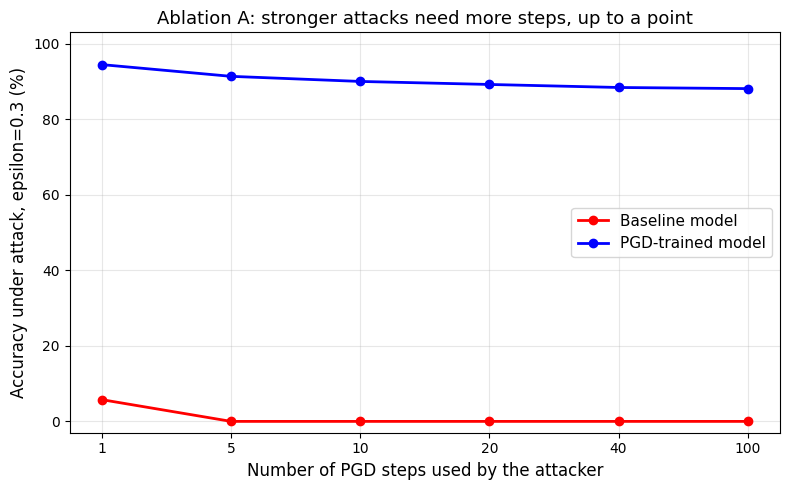

In [3]:
# CELL 3 - Ablation A: how many PGD steps does the attacker need?
#
# Notebooks 2 and 3 used 40 PGD steps. Is that enough, or would a more
# patient attacker do much better? If accuracy keeps falling as we add
# steps, our robustness numbers were too optimistic. If it levels off,
# 40 steps is a fair test.
# We also check whether the random starting point matters.

print("Ablation A: number of PGD steps (attack side)")
print("=" * 55)
print("This cell takes roughly 3-6 minutes on CPU.\n")

step_counts = [1, 5, 10, 20, 40, 100]
steps_results = []
print(f"{'PGD steps':>10} {'Baseline':>10} {'PGD-trained':>13}")
print("-" * 36)
for k in step_counts:
    acc_base = robust_accuracy(baseline_model,
                               lambda m, x, y: pgd_attack(m, x, y, EPSILON, steps=k))
    acc_rob  = robust_accuracy(pgd_trained_model,
                               lambda m, x, y: pgd_attack(m, x, y, EPSILON, steps=k))
    steps_results.append((k, acc_base, acc_rob))
    print(f"{k:>10} {acc_base:>9.2f}% {acc_rob:>12.2f}%")

no_random_start = robust_accuracy(
    pgd_trained_model,
    lambda m, x, y: pgd_attack(m, x, y, EPSILON, steps=40, random_start=False))
with_random_start = [r[2] for r in steps_results if r[0] == 40][0]
print(f"\nPGD-trained model, 40 steps, with random start   : {with_random_start:.2f}%")
print(f"PGD-trained model, 40 steps, without random start: {no_random_start:.2f}%")

plt.figure(figsize=(8, 5))
plt.plot([str(r[0]) for r in steps_results], [r[1] for r in steps_results],
         'r-o', linewidth=2, label='Baseline model')
plt.plot([str(r[0]) for r in steps_results], [r[2] for r in steps_results],
         'b-o', linewidth=2, label='PGD-trained model')
plt.xlabel('Number of PGD steps used by the attacker', fontsize=12)
plt.ylabel(f'Accuracy under attack, epsilon={EPSILON} (%)', fontsize=12)
plt.title('Ablation A: stronger attacks need more steps, up to a point', fontsize=13)
plt.ylim(-3, 103)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/ablation_attack_steps.png', dpi=150)
plt.show()

Ablations B and C: adversarial training settings
This cell trains 6 models and takes roughly 30-50 minutes on CPU.



10 steps, eps 0.2 epoch 2/2: 100%|███████████████████████████████████████████████████| 938/938 [03:02<00:00,  5.15it/s]



Ablation B: PGD steps used during training (all trained with epsilon 0.3)
Training setting                    Clean   FGSM 0.3   PGD 0.3
--------------------------------------------------------------
1 step, eps 0.3                    98.15%     97.30%     0.00%
3 steps, eps 0.3                   98.10%     88.15%    62.45%
10 steps, eps 0.3 (reference)      97.35%     90.25%    80.40%
10 steps, eps 0.3, adv. only       68.05%     50.20%    42.95%

Ablation C: accuracy under PGD for each training / attack epsilon
Model                       Clean   PGD 0.1   PGD 0.2   PGD 0.3
--------------------------------------------------------------
Baseline (no defense)      98.60%    67.40%     0.35%     0.00%
Trained with eps 0.1       98.30%    93.35%    58.50%     0.10%
Trained with eps 0.2       98.15%    94.60%    86.05%     9.60%
Trained with eps 0.3       97.35%    92.15%    87.90%    80.40%


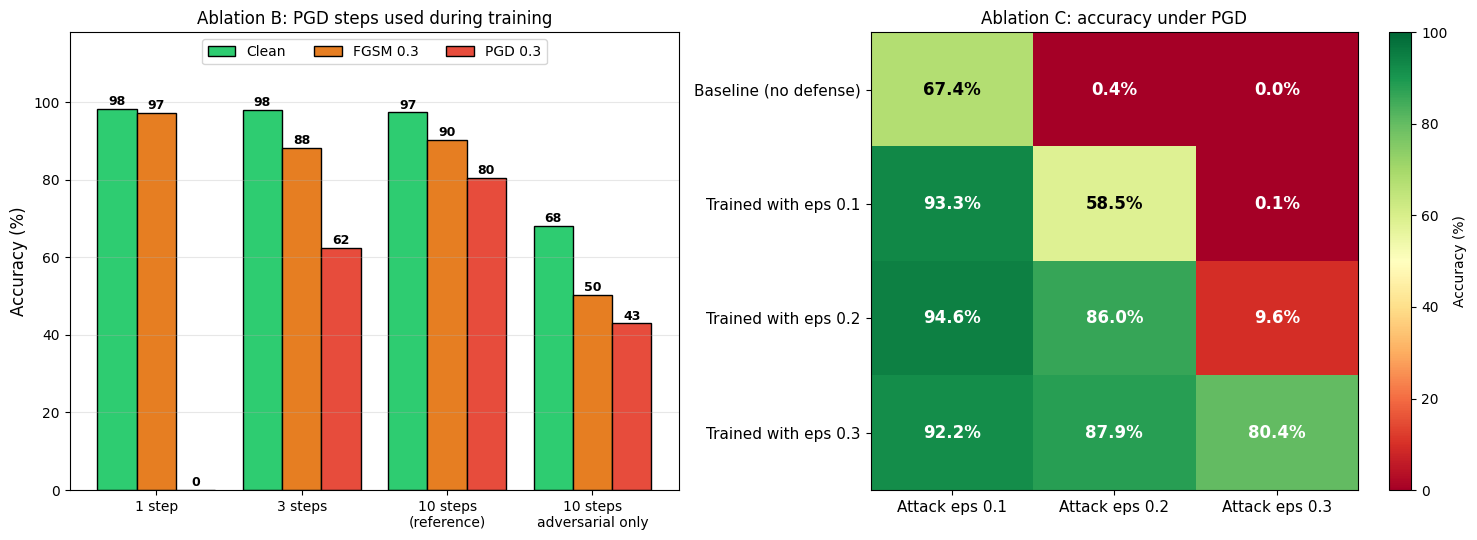

In [4]:
# CELL 4 - Ablations B and C: what matters in adversarial training?
#
# Notebook 3 showed that FGSM training (1 step) fails against PGD while
# PGD training (10 steps) works. Here we look closer:
#   B. Steps during training : 1, 3 or 10 PGD steps per batch (epsilon 0.3)
#      and whether mixing in clean images matters (10 steps, adversarial only)
#   C. Training epsilon      : train with 0.1, 0.2 or 0.3, then attack with
#                              0.1, 0.2 and 0.3
# To keep the running time reasonable every model here is trained for
# 2 epochs (notebook 3 used 5), so the absolute numbers are lower than in
# notebook 3. What matters is the comparison BETWEEN the rows.

def adversarial_training(train_epsilon, train_steps, clean_weight=0.5,
                         epochs=2, batch_size=64, name=""):
    torch.manual_seed(0)
    model = SimpleCNN()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()
    n = len(X_train)
    for epoch in range(epochs):
        order = torch.randperm(n)
        for i in tqdm(range(0, n, batch_size), desc=f"{name} epoch {epoch+1}/{epochs}"):
            idx = order[i:i + batch_size]
            images, labels = X_train[idx], y_train[idx]
            model.eval()
            adv_images = pgd_attack(model, images, labels, train_epsilon, steps=train_steps)
            model.train()
            optimizer.zero_grad()
            loss = (1 - clean_weight) * criterion(model(adv_images), labels)
            if clean_weight > 0:
                loss = loss + clean_weight * criterion(model(images), labels)
            loss.backward()
            optimizer.step()
    model.eval()
    return model

print("Ablations B and C: adversarial training settings")
print("=" * 55)
print("This cell trains 6 models and takes roughly 30-50 minutes on CPU.\n")

configs = [
    # name,                          train eps, steps, clean weight
    ("1 step, eps 0.3",                  0.3,    1,     0.5),
    ("3 steps, eps 0.3",                 0.3,    3,     0.5),
    ("10 steps, eps 0.3 (reference)",    0.3,   10,     0.5),
    ("10 steps, eps 0.3, adv. only",     0.3,   10,     0.0),
    ("10 steps, eps 0.1",                0.1,   10,     0.5),
    ("10 steps, eps 0.2",                0.2,   10,     0.5),
]

ablation_models = {}
for name, train_eps, train_steps, clean_weight in configs:
    ablation_models[name] = adversarial_training(train_eps, train_steps, clean_weight,
                                                 name=name)

# ---- Ablation B: steps during training, and the clean/adversarial mix ----
print("\nAblation B: PGD steps used during training (all trained with epsilon 0.3)")
print(f"{'Training setting':<32} {'Clean':>8} {'FGSM 0.3':>10} {'PGD 0.3':>9}")
print("-" * 62)
training_results = []
for name in [c[0] for c in configs[:4]]:
    model = ablation_models[name]
    clean = accuracy(model, X_eval, y_eval)
    fgsm  = robust_accuracy(model, lambda m, x, y: fgsm_attack(m, x, y, EPSILON))
    pgd   = robust_accuracy(model, lambda m, x, y: pgd_attack(m, x, y, EPSILON))
    training_results.append((name, clean, fgsm, pgd))
    print(f"{name:<32} {clean:>7.2f}% {fgsm:>9.2f}% {pgd:>8.2f}%")

# ---- Ablation C: training epsilon vs attack epsilon ----
eps_values = [0.1, 0.2, 0.3]
eps_models = [("Baseline (no defense)", baseline_model),
              ("Trained with eps 0.1", ablation_models["10 steps, eps 0.1"]),
              ("Trained with eps 0.2", ablation_models["10 steps, eps 0.2"]),
              ("Trained with eps 0.3", ablation_models["10 steps, eps 0.3 (reference)"])]

print("\nAblation C: accuracy under PGD for each training / attack epsilon")
print(f"{'Model':<24} {'Clean':>8} " + " ".join(f"{'PGD ' + str(e):>9}" for e in eps_values))
print("-" * 62)
eps_matrix = []
for name, model in eps_models:
    row = [accuracy(model, X_eval, y_eval)]
    for e in eps_values:
        row.append(robust_accuracy(model, lambda m, x, y: pgd_attack(m, x, y, e)))
    eps_matrix.append((name, row))
    print(f"{name:<24} {row[0]:>7.2f}% " + " ".join(f"{v:>8.2f}%" for v in row[1:]))

# Figures
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

pos = np.arange(len(training_results))
width = 0.27
for k, (label, color) in enumerate([("Clean", '#2ecc71'), ("FGSM 0.3", '#e67e22'),
                                    ("PGD 0.3", '#e74c3c')]):
    vals = [r[k + 1] for r in training_results]
    bars = axes[0].bar(pos + (k - 1) * width, vals, width, label=label,
                       color=color, edgecolor='black')
    for bar in bars:
        axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
                     f"{bar.get_height():.0f}", ha='center', fontsize=9, fontweight='bold')
axes[0].set_xticks(pos)
axes[0].set_xticklabels([r[0].replace(", eps 0.3", "").replace(" (reference)", "\n(reference)")
                         .replace(", adv. only", "\nadversarial only")
                         for r in training_results], fontsize=10)
axes[0].set_ylabel('Accuracy (%)', fontsize=12)
axes[0].set_title('Ablation B: PGD steps used during training', fontsize=12)
axes[0].set_ylim(0, 118)
axes[0].legend(fontsize=10, loc='upper center', ncol=3)
axes[0].grid(axis='y', alpha=0.3)

matrix = np.array([row[1:] for _, row in eps_matrix])
im = axes[1].imshow(matrix, cmap='RdYlGn', vmin=0, vmax=100, aspect='auto')
axes[1].set_xticks(range(len(eps_values)))
axes[1].set_xticklabels([f"Attack eps {e}" for e in eps_values], fontsize=11)
axes[1].set_yticks(range(len(eps_matrix)))
axes[1].set_yticklabels([name for name, _ in eps_matrix], fontsize=11)
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        v = matrix[i, j]
        axes[1].text(j, i, f"{v:.1f}%", ha='center', va='center', fontsize=12,
                     fontweight='bold', color='black' if 30 < v < 80 else 'white')
axes[1].set_title('Ablation C: accuracy under PGD', fontsize=12)
plt.colorbar(im, ax=axes[1], label='Accuracy (%)')
plt.tight_layout()
plt.savefig('../figures/ablation_adversarial_training.png', dpi=150)
plt.show()

Ablation D: input preprocessing at different attack strengths
This cell takes roughly 3-6 minutes on CPU.



Creating PGD examples: 100%|█████████████████████████████████████████████████████████████| 3/3 [01:02<00:00, 20.96s/it]



Preprocessing                 Clean   PGD 0.1   PGD 0.2   PGD 0.3
----------------------------------------------------------
No preprocessing             98.60%    67.40%     0.35%     0.00%
Gaussian blur, sigma 0.5     98.40%    78.40%     4.40%     0.00%
Gaussian blur, sigma 1.0     98.05%    87.40%    37.25%     0.85%
Gaussian blur, sigma 2.0     95.25%    88.20%    69.80%    37.15%
Bit depth, 4 bits            98.55%    79.35%     0.45%     0.00%
Bit depth, 2 bits            98.60%    95.20%     0.00%     0.00%
Bit depth, 1 bit             98.65%    96.40%    90.90%    82.30%


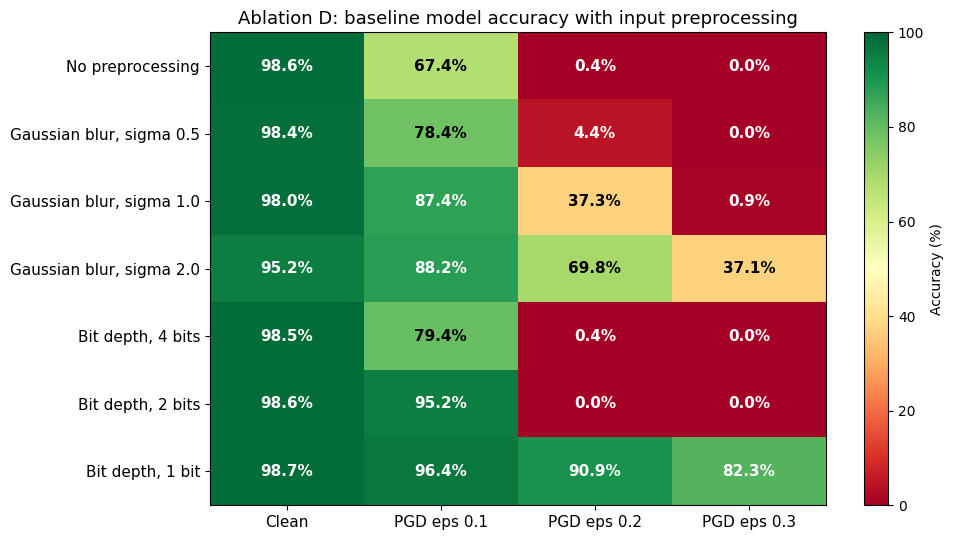

In [5]:
# CELL 5 - Ablation D: do preprocessing defenses work at ANY attack strength?
#
# In notebook 3 Gaussian smoothing and bit-depth reduction gave almost no
# protection at epsilon 0.3. Here we test weaker attacks and different
# preprocessing strengths, to see whether these defenses are useless or
# just limited to small perturbations.
# As in notebook 3, the attacker does not know about the preprocessing.

def gaussian_smoothing(images, sigma=1.0, kernel_size=3):
    x = torch.arange(kernel_size).float() - kernel_size // 2
    gauss = torch.exp(-x ** 2 / (2 * sigma ** 2))
    gauss = gauss / gauss.sum()
    kernel = (gauss.unsqueeze(0) * gauss.unsqueeze(1)).view(1, 1, kernel_size, kernel_size)
    return F.conv2d(images, kernel, padding=kernel_size // 2)

def bit_depth_reduction(images, bits=4):
    pixels = (images * STD + MEAN).clamp(0, 1)
    levels = 2 ** bits - 1
    pixels = torch.round(pixels * levels) / levels
    return (pixels - MEAN) / STD

print("Ablation D: input preprocessing at different attack strengths")
print("=" * 55)
print("This cell takes roughly 3-6 minutes on CPU.\n")

preprocessors = [
    ("No preprocessing",        lambda x: x),
    ("Gaussian blur, sigma 0.5", lambda x: gaussian_smoothing(x, sigma=0.5)),
    ("Gaussian blur, sigma 1.0", lambda x: gaussian_smoothing(x, sigma=1.0)),
    ("Gaussian blur, sigma 2.0", lambda x: gaussian_smoothing(x, sigma=2.0, kernel_size=5)),
    ("Bit depth, 4 bits",        lambda x: bit_depth_reduction(x, bits=4)),
    ("Bit depth, 2 bits",        lambda x: bit_depth_reduction(x, bits=2)),
    ("Bit depth, 1 bit",         lambda x: bit_depth_reduction(x, bits=1)),
]

attack_eps = [0.1, 0.2, 0.3]
# Adversarial images are made once per epsilon against the plain baseline model
pgd_examples = {e: attack_in_batches(lambda m, x, y: pgd_attack(m, x, y, e),
                                     baseline_model, X_eval, y_eval)
                for e in tqdm(attack_eps, desc="Creating PGD examples")}

print(f"\n{'Preprocessing':<26} {'Clean':>8} " +
      " ".join(f"{'PGD ' + str(e):>9}" for e in attack_eps))
print("-" * 58)
preprocessing_results = []
for name, fn in preprocessors:
    row = [accuracy(baseline_model, fn(X_eval), y_eval)]
    for e in attack_eps:
        row.append(accuracy(baseline_model, fn(pgd_examples[e]), y_eval))
    preprocessing_results.append((name, row))
    print(f"{name:<26} {row[0]:>7.2f}% " + " ".join(f"{v:>8.2f}%" for v in row[1:]))

fig, ax = plt.subplots(figsize=(10, 5.5))
matrix = np.array([row for _, row in preprocessing_results])
im = ax.imshow(matrix, cmap='RdYlGn', vmin=0, vmax=100, aspect='auto')
ax.set_xticks(range(4))
ax.set_xticklabels(["Clean"] + [f"PGD eps {e}" for e in attack_eps], fontsize=11)
ax.set_yticks(range(len(preprocessing_results)))
ax.set_yticklabels([name for name, _ in preprocessing_results], fontsize=11)
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        v = matrix[i, j]
        ax.text(j, i, f"{v:.1f}%", ha='center', va='center', fontsize=11,
                fontweight='bold', color='black' if 30 < v < 80 else 'white')
ax.set_title('Ablation D: baseline model accuracy with input preprocessing', fontsize=13)
plt.colorbar(im, ax=ax, label='Accuracy (%)')
plt.tight_layout()
plt.savefig('../figures/ablation_preprocessing.png', dpi=150)
plt.show()

In [6]:
# CELL 6 - Save the ablation results

with open('../results/ablation_results.txt', 'w') as f:
    f.write("ABLATION STUDY RESULTS\n")
    f.write("=" * 62 + "\n")
    f.write(f"MNIST, {N_EVAL} test images per measurement, "
            f"epsilon in pixel units (0-1 scale)\n\n")

    f.write(f"A. Number of PGD steps used by the attacker (epsilon {EPSILON})\n")
    f.write(f"{'PGD steps':>10} {'Baseline':>10} {'PGD-trained':>13}\n")
    for k, acc_base, acc_rob in steps_results:
        f.write(f"{k:>10} {acc_base:>9.2f}% {acc_rob:>12.2f}%\n")
    f.write(f"PGD-trained, 40 steps, without random start: {no_random_start:.2f}%\n\n")

    f.write("B. PGD steps used during adversarial training "
            "(epsilon 0.3, 2 epochs)\n")
    f.write(f"{'Training setting':<32} {'Clean':>8} {'FGSM 0.3':>10} {'PGD 0.3':>9}\n")
    for name, clean, fgsm, pgd in training_results:
        f.write(f"{name:<32} {clean:>7.2f}% {fgsm:>9.2f}% {pgd:>8.2f}%\n")

    f.write("\nC. Training epsilon vs attack epsilon "
            "(10 training steps, 2 epochs; accuracy under PGD-40)\n")
    f.write(f"{'Model':<24} {'Clean':>8} " +
            " ".join(f"{'PGD ' + str(e):>9}" for e in eps_values) + "\n")
    for name, row in eps_matrix:
        f.write(f"{name:<24} {row[0]:>7.2f}% " +
                " ".join(f"{v:>8.2f}%" for v in row[1:]) + "\n")

    f.write("\nD. Input preprocessing on the baseline model (accuracy under PGD-40)\n")
    f.write(f"{'Preprocessing':<26} {'Clean':>8} " +
            " ".join(f"{'PGD ' + str(e):>9}" for e in attack_eps) + "\n")
    for name, row in preprocessing_results:
        f.write(f"{name:<26} {row[0]:>7.2f}% " +
                " ".join(f"{v:>8.2f}%" for v in row[1:]) + "\n")

print("Ablation results saved to results/ablation_results.txt")
print("Figures saved to figures/ablation_*.png")

Ablation results saved to results/ablation_results.txt
Figures saved to figures/ablation_*.png
